# AI Food Waste & Expiry Tracker
**AI Foundations for Managers · Semester 1, 2026 · Group project notebook**

**Business problem.** Households throw away food they paid for: milk that turns, bread that goes stale, greens forgotten at the back of the fridge. Indian homes waste roughly **55 kg of food per person per year**, and households produce about **60% of all food waste worldwide** (UNEP Food Waste Index Report 2024). For a family this is lost money every month; for society it is wasted water, land and emissions.

**Our solution – an AI-powered mobile app (prototype) that:**
1. **Predicts which items in the pantry are likely to be wasted** and sends a small number of well-targeted "use it up" alerts (AI Model 1 – classification).
2. **Forecasts how much the household will actually use next week** and builds a smart shopping list so they buy less of what they waste (AI Model 2 – forecasting).
3. Suggests **recipes** that use the at-risk items first.

**Stakeholders:** households (primary users), grocery / quick-commerce partners, app business (subscription or partner revenue), and the environment / city waste systems.

| Decision | Current process | AI-supported process |
|---|---|---|
| Which items should I use first? | Memory, or checking printed dates | Risk score per item; alert only when waste is likely |
| How much should I buy? | Habit and promotions | Forecast of next week's use, minus what is already at home |

> **Data note:** all data in this notebook is **synthetic**, generated below (400 households, 12 weeks), as allowed by the project brief.

## Step 1 – Generate synthetic data

In [1]:
# STEP 1A: Import libraries
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
np.random.seed(42)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
GREEN, TOMATO, AMBER, GREY = "#2F6B4F", "#E4572E", "#F2A541", "#A9B3B0"
print("Libraries imported")

Libraries imported


**STEP 1B – The simulator.** Each household has a size, diet, shopping days and habits (how much they over-buy, whether they check the fridge before shopping, whether they store food correctly, how often plans change). Every purchase becomes a *lot* with a storage place and an expiry date. Each day the household eats from its pantry, first-expiring first; whatever is left at expiry is **wasted**. Three data-quality problems are added on purpose.

In [2]:
%%writefile generate_data.py
"""
Synthetic household pantry simulator – AI Food Waste & Expiry Tracker
400 households x 15 grocery categories x 84 days (12 weeks).
Each purchase is a 'lot' with a storage place and expiry date; households eat from
their pantry day by day (first-expiring first) and whatever is left at expiry is wasted.
ALL DATA IS SYNTHETIC.
"""
import os
import numpy as np
import pandas as pd

SEED, N_HH, N_DAYS = 7, 400, 84
OUT = "data"
rng = np.random.default_rng(SEED)

# ---------------------------------------------------------------- catalogue
# name, unit, kg per unit, price (Rs), shelf life by storage, best storage, common worse storage, daily units per person
CAT = [
    ("Milk",          "1 L pack",    1.00,  62, {"fridge": 3,  "pantry": 1},   "fridge", "fridge", 0.22),
    ("Curd",          "400 g tub",   0.40,  45, {"fridge": 6,  "pantry": 2},   "fridge", "fridge", 0.08),
    ("Paneer",        "200 g pack",  0.20,  95, {"fridge": 4,  "freezer": 30}, "fridge", "fridge", 0.04),
    ("Bread",         "400 g loaf",  0.40,  45, {"pantry": 4,  "fridge": 6},   "fridge", "pantry", 0.07),
    ("Eggs",          "6 eggs",      0.36,  48, {"fridge": 18, "pantry": 7},   "fridge", "pantry", 0.08),
    ("Bananas",       "6 bananas",   0.70,  50, {"pantry": 4,  "fridge": 6},   "pantry", "pantry", 0.06),
    ("Apples",        "1 kg",        1.00, 180, {"fridge": 20, "pantry": 8},   "fridge", "pantry", 0.03),
    ("Tomatoes",      "1 kg",        1.00,  40, {"pantry": 5,  "fridge": 9},   "fridge", "pantry", 0.06),
    ("Leafy greens",  "250 g bunch", 0.25,  30, {"fridge": 3,  "pantry": 1},   "fridge", "fridge", 0.07),
    ("Coriander",     "100 g bunch", 0.10,  15, {"fridge": 5,  "pantry": 2},   "fridge", "pantry", 0.06),
    ("Onions",        "1 kg",        1.00,  35, {"pantry": 30},                "pantry", "pantry", 0.07),
    ("Chicken",       "500 g",       0.50, 160, {"fridge": 2,  "freezer": 60}, "freezer", "fridge", 0.04),
    ("Cheese",        "200 g",       0.20, 120, {"fridge": 25},                "fridge", "fridge", 0.02),
    ("Snacks",        "1 pack",      0.20,  50, {"pantry": 90},                "pantry", "pantry", 0.05),
    ("Rice & atta",   "5 kg bag",    5.00, 300, {"pantry": 180},               "pantry", "pantry", 0.006),
]
CATS = pd.DataFrame(CAT, columns=["category", "unit", "kg_per_unit", "price", "shelf", "best_storage", "worse_storage", "rate"])
CATS["shelf_life_best"] = [s[b] for s, b in zip(CATS.shelf, CATS.best_storage)]
NC = len(CATS)
NONVEG = {"Chicken", "Eggs"}

# ---------------------------------------------------------------- households
size = rng.choice([1, 2, 3, 4, 5, 6], N_HH, p=[.15, .22, .20, .25, .12, .06])
hh = pd.DataFrame({
    "household_id": [f"H{i:03d}" for i in range(1, N_HH + 1)],
    "household_size": size,
    "household_type": np.select([size == 1, size == 2, size <= 4], ["Single", "Couple", "Family"], "Joint family"),
    "vegetarian": rng.random(N_HH) < 0.45,
    "cook_days_per_week": rng.integers(3, 8, N_HH),
    "shops_per_week": rng.choice([1, 2, 3], N_HH, p=[.35, .45, .20]),
    "overbuy": np.clip(rng.lognormal(0.04, 0.16, N_HH), 0.85, 1.8),      # buys more than needed
    "pantry_awareness": rng.uniform(0.2, 0.9, N_HH),                       # checks what is at home
    "stores_correctly": rng.uniform(0.45, 0.95, N_HH),                     # uses best storage
    "eat_out_rate": rng.uniform(0.03, 0.30, N_HH),                         # plans change
})
pref = rng.uniform(0.5, 1.5, (N_HH, NC)) * (rng.random((N_HH, NC)) < 0.85)
for i, v in enumerate(hh.vegetarian):
    if v:
        for j, c in enumerate(CATS.category):
            if c in NONVEG: pref[i, j] = 0
pref[:, CATS.category.tolist().index("Onions")] = np.maximum(pref[:, CATS.category.tolist().index("Onions")], 0.6)

# ---------------------------------------------------------------- daily demand (units of each category)
dow = np.arange(N_DAYS) % 7
weekend = np.isin(dow, [5, 6]).astype(float)
festival = ((np.arange(N_DAYS) // 7) == 8).astype(float)             # festival week (week 9)
demand = np.zeros((N_HH, NC, N_DAYS))
for i in range(N_HH):
    eat_out = rng.random(N_DAYS) < hh.eat_out_rate[i]
    cook = hh.cook_days_per_week[i] / 7
    base = hh.household_size[i] * CATS.rate.values * pref[i]
    for j in range(NC):
        mult = (1 + 0.2 * weekend + 0.3 * festival) * np.where(eat_out, 0.35, 1.0) * (0.6 + 0.6 * cook)
        demand[i, j] = base[j] * mult * rng.gamma(6, 1 / 6, N_DAYS)

# ---------------------------------------------------------------- simulate pantry
lots, consumed_log = [], np.zeros((N_HH, NC, N_DAYS))
open_lots_end = []
lot_id = 0
SHOP_DOWS = [''] * N_HH
for i in range(N_HH):
    k = hh.shops_per_week[i]
    shop_dows = sorted(rng.choice(7, k, replace=False))
    SHOP_DOWS[i] = " ".join(map(str, shop_dows))
    shop_days = [d for d in range(N_DAYS) if d % 7 in shop_dows]
    for j in range(NC):
        if pref[i, j] == 0: continue
        cat = CATS.iloc[j]
        pantry = []                               # [lot_index, remaining, expiry_day]
        hist_use = []
        # very short-life items (milk) are bought on a daily top-up; others on shopping days
        my_days = list(range(0, N_DAYS, 2)) if cat.shelf_life_best <= 3 else shop_days
        for d in range(N_DAYS):
            if d in my_days:
                nxt = next((s for s in my_days if s > d), d + 7)
                gap = min(nxt - d, cat.shelf_life_best + 1)
                exp_need = hh.household_size[i] * cat.rate * pref[i, j] * gap
                on_hand = sum(p[1] for p in pantry)
                promo = rng.random() < 0.12
                want = exp_need * hh.overbuy[i] * rng.uniform(0.8, 1.25) - hh.pantry_awareness[i] * on_hand
                if promo: want *= rng.uniform(1.5, 2.2)
                # minimum pack: if anything is needed and stock is low, buy at least 1
                qty = int(np.ceil(want)) if want > 0.25 else 0
                if cat.category in ("Rice & atta", "Snacks"):
                    qty = 1 if on_hand < hh.household_size[i] * cat.rate * pref[i, j] * 7 else 0
                if qty > 0:
                    good = rng.random() < hh.stores_correctly[i]
                    storage = cat.best_storage if good else cat.worse_storage
                    if storage not in cat.shelf: storage = cat.best_storage
                    life = max(1, int(round(cat.shelf[storage] * rng.uniform(0.85, 1.15))))
                    past = np.mean(hist_use[-28:]) if len(hist_use) >= 7 else hh.household_size[i] * cat.rate
                    lots.append(dict(lot_id=lot_id, household_id=hh.household_id[i], category=cat.category, day=d,
                                     week=d // 7, storage=storage, shelf_life_days=life, quantity_units=qty,
                                     unit_price=cat.price, bought_on_promo=int(promo), on_hand_units=round(on_hand, 2),
                                     est_daily_use=round(max(past, 0.01), 4), expiry_day=d + life,
                                     wasted_units=0.0))
                    pantry.append([len(lots) - 1, float(qty), d + life])
                    lot_id += 1
            # eat: first-expiring first
            need = demand[i, j, d]
            pantry.sort(key=lambda p: p[2])
            eaten = 0.0
            for p in pantry:
                if need <= 0: break
                take = min(p[1], need); p[1] -= take; need -= take; eaten += take
            consumed_log[i, j, d] = eaten
            hist_use.append(demand[i, j, d])
            # waste whatever expires today
            keep = []
            for p in pantry:
                if p[2] <= d and p[1] > 1e-6:
                    lots[p[0]]["wasted_units"] += p[1]
                elif p[1] > 1e-6:
                    keep.append(p)
            pantry = keep
        for p in pantry:
            open_lots_end.append(dict(lot_id=p[0], remaining_units=p[1]))

lots = pd.DataFrame(lots)
lots = lots.merge(hh[["household_id", "household_size", "cook_days_per_week", "eat_out_rate", "vegetarian"]], on="household_id")
lots = lots.merge(CATS[["category", "kg_per_unit"]], on="category")
lots["value"] = lots.quantity_units * lots.unit_price
lots["wasted_fraction"] = (lots.wasted_units / lots.quantity_units).round(4)
lots["wasted_value"] = (lots.wasted_units * lots.unit_price).round(2)
lots["wasted_kg"] = (lots.wasted_units * lots.kg_per_unit).round(3)
lots["complete"] = (lots.expiry_day <= N_DAYS - 1).astype(int)

weekly = pd.DataFrame([dict(household_id=hh.household_id[i], category=CATS.category[j], week=w,
                            demand_units=round(demand[i, j, w * 7:(w + 1) * 7].sum(), 3))
                       for i in range(N_HH) for j in range(NC) if pref[i, j] > 0 for w in range(N_DAYS // 7)])

# current pantry ("today" = day 83) for the app
op = pd.DataFrame(open_lots_end).merge(lots, on="lot_id")
op["days_left"] = op.expiry_day - (N_DAYS - 1)
current = op[op.days_left > 0][["household_id", "category", "storage", "shelf_life_days", "quantity_units", "remaining_units",
                                "unit_price", "bought_on_promo", "on_hand_units", "est_daily_use", "day", "days_left"]].copy()
current["remaining_units"] = current.remaining_units.round(2)

# daily demand saved compactly for the back-test (weeks 9-12 only)
dd = [dict(household_id=hh.household_id[i], category=CATS.category[j], day=d, demand_units=round(demand[i, j, d], 4))
      for i in range(N_HH) for j in range(NC) if pref[i, j] > 0 for d in range(56, N_DAYS)]
daily = pd.DataFrame(dd)

# realistic data-quality issues in the raw purchase log
raw = lots.copy()
dup = raw.sample(frac=0.01, random_state=1)
raw = pd.concat([raw, dup]).reset_index(drop=True)
raw.loc[raw.sample(frac=0.02, random_state=2).index, "storage"] = np.nan                  # not recorded
raw.loc[raw.sample(frac=0.004, random_state=3).index, "quantity_units"] = 0               # scanner error

os.makedirs(OUT, exist_ok=True)
hh["shop_days"] = SHOP_DOWS
hh.to_csv(f"{OUT}/households.csv", index=False)
pd.DataFrame(pref, columns=CATS.category).assign(household_id=hh.household_id).to_csv(f"{OUT}/preferences.csv", index=False)
CATS.drop(columns=["shelf"]).to_csv(f"{OUT}/categories.csv", index=False)
raw.to_csv(f"{OUT}/purchases_raw.csv", index=False)
weekly.to_csv(f"{OUT}/weekly_demand.csv", index=False)
daily.to_csv(f"{OUT}/daily_demand_backtest.csv", index=False)
current.to_csv(f"{OUT}/current_pantry.csv", index=False)
print(f"households={len(hh)} purchases={len(raw):,} weekly_rows={len(weekly):,} current_items={len(current):,}")

Overwriting generate_data.py


In [3]:
# STEP 1C: Run the simulator (about 1 minute)
if not os.path.exists("data/purchases_raw.csv"):
    !python generate_data.py
households = pd.read_csv("data/households.csv")
categories = pd.read_csv("data/categories.csv")
raw = pd.read_csv("data/purchases_raw.csv")
print("Households:", len(households), "| Purchases (raw):", f"{len(raw):,}")
display(raw.head())

Households: 400 | Purchases (raw): 68,939


,lot_id,household_id,category,day,week,storage,shelf_life_days,quantity_units,unit_price,bought_on_promo,...,household_size,cook_days_per_week,eat_out_rate,vegetarian,kg_per_unit,value,wasted_fraction,wasted_value,wasted_kg,complete
0,0,H001,Milk,0,0,fridge,3,4,62,0,...,4,6,0.235829,True,1.0,248,0.3488,86.50,1.395,1
1,1,H001,Milk,2,0,NaN,3,2,62,0,...,4,6,0.235829,True,1.0,124,0.0000,0.00,0.000,1
2,2,H001,Milk,4,0,fridge,3,3,62,0,...,4,6,0.235829,True,1.0,186,0.0000,0.00,0.000,1
3,3,H001,Milk,6,0,fridge,3,3,62,0,...,4,6,0.235829,True,1.0,186,0.5031,93.57,1.509,1
4,4,H001,Milk,8,1,fridge,3,2,62,0,...,4,6,0.235829,True,1.0,124,0.0759,9.41,0.152,1


## Step 2 – Data quality and cleaning

In [4]:
# STEP 2A: Data-quality report
quality = pd.DataFrame({
    "Check": ["Rows", "Duplicate purchase records", "Storage place not recorded", "Quantity = 0 (scanner error)"],
    "Result": [len(raw), int(raw.duplicated("lot_id").sum()), int(raw.storage.isna().sum()), int((raw.quantity_units <= 0).sum())]})
display(quality)

,Check,Result
0,Rows,68939
1,Duplicate purchase records,683
2,Storage place not recorded,1379
3,Quantity = 0 (scanner error),276


In [5]:
# STEP 2B: Clean
purchases = raw.drop_duplicates("lot_id").copy()
purchases = purchases[purchases.quantity_units > 0]
# Missing storage -> the most common storage for that category
mode_storage = purchases.groupby("category").storage.agg(lambda s: s.mode().iat[0])
purchases["storage"] = purchases.storage.fillna(purchases.category.map(mode_storage))
# Keep purchases whose outcome is known (expired before the last day)
purchases = purchases[purchases.complete == 1].reset_index(drop=True)
purchases["wasted"] = (purchases.wasted_fraction >= 0.20).astype(int)     # target: 20%+ of the item thrown away
print("Clean purchases with known outcome:", f"{len(purchases):,}")
print("Missing values left:", purchases[["storage", "quantity_units"]].isna().sum().sum())
print(f"Items with meaningful waste (≥20% thrown away): {purchases.wasted.mean():.1%}")

Clean purchases with known outcome: 56,247
Missing values left: 0
Items with meaningful waste (≥20% thrown away): 43.8%


## Step 3 – How big is the problem?

In [6]:
# STEP 3A: Headline numbers
months = 84 / 30
hh_month = purchases.groupby("household_id").agg(wasted_value=("wasted_value", "sum"), wasted_kg=("wasted_kg", "sum"),
                                                  size=("household_size", "first"))
headline = pd.Series({
    "Share of food spend wasted (%)": purchases.wasted_value.sum() / purchases.value.sum() * 100,
    "Average waste per household per month (₹)": hh_month.wasted_value.mean() / months,
    "Average waste per person per month (kg)": (hh_month.wasted_kg / hh_month["size"]).mean() / months,
    "Items with ≥20% wasted (%)": purchases.wasted.mean() * 100,
})
display(headline.round(1).to_frame("Value"))

,Value
Share of food spend wasted (%),22.5
Average waste per household per month (₹),914.9
Average waste per person per month (kg),3.3
Items with ≥20% wasted (%),43.8


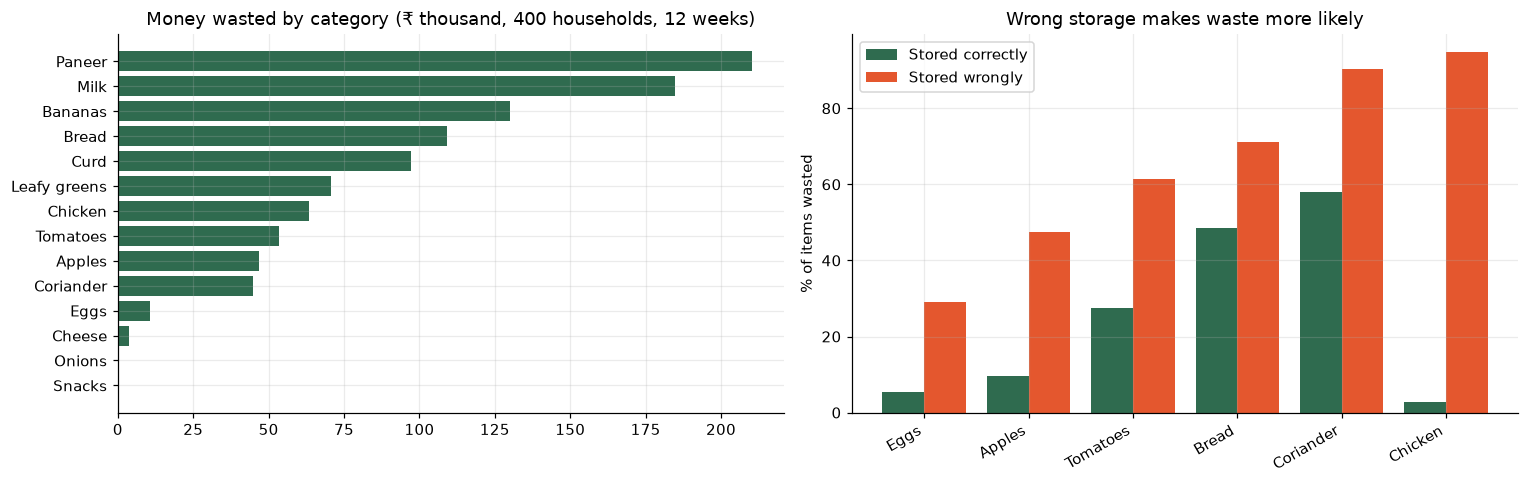

In [7]:
# STEP 3B: Where does the money go? Waste by category, and by storage choice
by_cat = purchases.groupby("category").agg(wasted_value=("wasted_value", "sum"), value=("value", "sum"))
by_cat["waste_rate_%"] = by_cat.wasted_value / by_cat.value * 100
by_cat = by_cat.sort_values("wasted_value")

purchases["stored_correctly"] = purchases.storage.eq(purchases.category.map(categories.set_index("category").best_storage))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].barh(by_cat.index, by_cat.wasted_value / 1000, color=GREEN)
ax[0].set_title("Money wasted by category (₹ thousand, 400 households, 12 weeks)")
st = purchases.groupby(["category", "stored_correctly"]).wasted.mean().unstack().dropna() * 100
st = st[st[False] > st[True]].sort_values(False)
x = np.arange(len(st)); ax[1].bar(x - .2, st[True], .4, label="Stored correctly", color=GREEN); ax[1].bar(x + .2, st[False], .4, label="Stored wrongly", color=TOMATO)
ax[1].set_xticks(x, st.index, rotation=30, ha="right"); ax[1].set_ylabel("% of items wasted"); ax[1].legend(); ax[1].set_title("Wrong storage makes waste more likely")
plt.tight_layout(); plt.show()

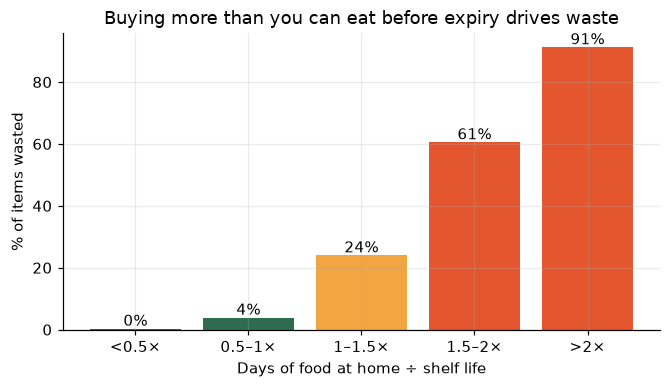

Bought on promotion: 61% wasted vs 41% at normal price


In [8]:
# STEP 3C: The key driver – buying more than you can use before it expires
purchases["cover_days"] = (purchases.on_hand_units + purchases.quantity_units) / purchases.est_daily_use
purchases["cover_ratio"] = purchases.cover_days / purchases.shelf_life_days
band = pd.cut(purchases.cover_ratio, [0, .5, 1, 1.5, 2, 1e9], labels=["<0.5×", "0.5–1×", "1–1.5×", "1.5–2×", ">2×"])
r = purchases.groupby(band, observed=True).wasted.mean() * 100
plt.figure(figsize=(7, 3.5)); b = plt.bar(r.index.astype(str), r.values, color=[GREEN, GREEN, AMBER, TOMATO, TOMATO])
for bar in b: plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, f"{bar.get_height():.0f}%", ha="center")
plt.xlabel("Days of food at home ÷ shelf life"); plt.ylabel("% of items wasted"); plt.title("Buying more than you can eat before expiry drives waste"); plt.show()
promo = purchases.groupby("bought_on_promo").wasted.mean() * 100
print(f"Bought on promotion: {promo[1]:.0f}% wasted vs {promo[0]:.0f}% at normal price")

## Step 4 – AI Model 1: Which items will be wasted?
**AI type:** supervised machine learning – binary classification (wasted = 1 if 20% or more of the item is thrown away).
**Inputs are things the app knows at purchase time:** category, storage place, shelf life, quantity, price, promotion, what is already at home, the household's typical daily use and its past waste rate.
**Split:** by time – purchases in weeks 5–10 train the model, weeks 11–12 test it (no peeking into the future).

In [9]:
# STEP 4A: Household's own waste history (previous 28 days) – a strong behavioural signal
purchases = purchases.sort_values(["household_id", "day"]).reset_index(drop=True)
global_rate = purchases.wasted.mean()
past_rate = np.full(len(purchases), global_rate)
for hid, g in purchases.groupby("household_id"):
    exp, w, days, idx = g.expiry_day.values, g.wasted.values, g.day.values, g.index.values
    for k in range(len(g)):
        mask = (exp < days[k]) & (exp >= days[k] - 28)
        if mask.sum() >= 3: past_rate[idx[k]] = w[mask].mean()
purchases["hh_past_waste_rate"] = past_rate
purchases = purchases.merge(households[["household_id", "cook_days_per_week"]].rename(columns={"cook_days_per_week": "cook_days"}), on="household_id")
print("Feature added: hh_past_waste_rate")

Feature added: hh_past_waste_rate


In [10]:
# STEP 4B: Features, split and preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay)
import joblib

CAT_FEATS = ["category", "storage"]
NUM_FEATS = ["shelf_life_days", "quantity_units", "unit_price", "bought_on_promo", "on_hand_units",
             "est_daily_use", "cover_days", "cover_ratio", "household_size", "cook_days", "hh_past_waste_rate"]
FEATURES = CAT_FEATS + NUM_FEATS

model_data = purchases[purchases.day >= 28].copy()            # first 4 weeks build history only
train = model_data[model_data.day < 70]; test = model_data[model_data.day >= 70]
X_train, y_train, X_test, y_test = train[FEATURES], train.wasted, test[FEATURES], test.wasted
prep = lambda: ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATS),
                                  ("num", StandardScaler(), NUM_FEATS)])
print(f"Train {len(train):,} items | Test {len(test):,} items | waste rate {y_train.mean():.1%}")

Train 28,993 items | Test 6,018 items | waste rate 43.3%


In [11]:
# STEP 4C: Train four models
models = {
    "Logistic Regression": Pipeline([("prep", prep()), ("clf", LogisticRegression(max_iter=2000))]),
    "Logistic Regression (balanced)": Pipeline([("prep", prep()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Random Forest": Pipeline([("prep", prep()), ("clf", RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=10,
                                                                                 class_weight="balanced", n_jobs=-1, random_state=42))]),
    "Gradient Boosting": Pipeline([("prep", prep()), ("clf", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06,
                                                                                             max_leaf_nodes=31, random_state=42))]),
}
for name, m in models.items():
    m.fit(X_train, y_train); print("Trained:", name)

Trained: Logistic Regression


Trained: Logistic Regression (balanced)


Trained: Random Forest


Trained: Gradient Boosting


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Explainable?
0,Logistic Regression,0.814,0.895,0.735,0.807,0.918,Yes – coefficients
1,Logistic Regression (balanced),0.824,0.875,0.779,0.824,0.919,Yes – coefficients
2,Random Forest,0.833,0.870,0.804,0.836,0.922,Partly – feature importance
3,Gradient Boosting,0.824,0.890,0.761,0.820,0.923,Partly – feature importance


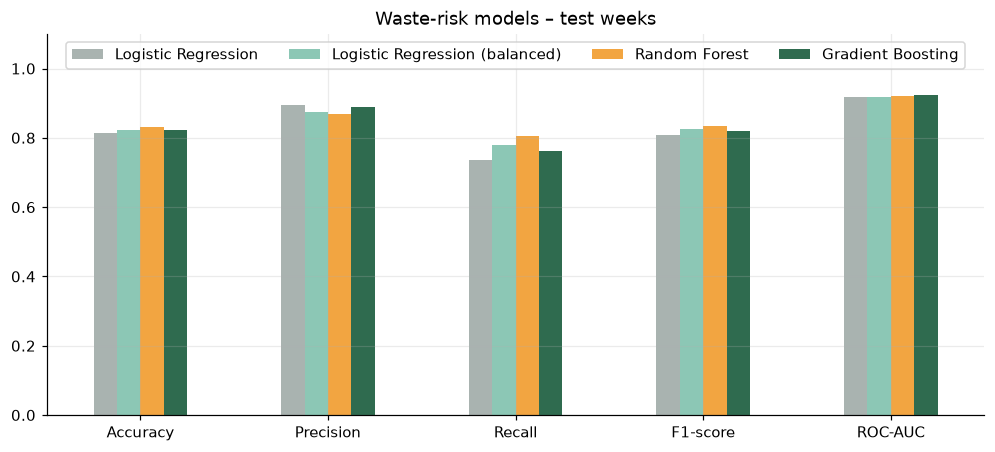

In [12]:
# STEP 4D: Compare on the test weeks
rows, probs = [], {}
for name, m in models.items():
    p = m.predict_proba(X_test)[:, 1]; pred = (p >= 0.5).astype(int); probs[name] = p
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1-score": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, p),
                 "Explainable?": "Yes – coefficients" if "Logistic" in name else "Partly – feature importance"})
comparison = pd.DataFrame(rows)
display(comparison.round(3))
mets = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
comparison.set_index("Model")[mets].T.plot(kind="bar", figsize=(11, 4.5), color=[GREY, "#8CC7B5", AMBER, GREEN])
plt.ylim(0, 1.1); plt.xticks(rotation=0); plt.legend(ncol=4, loc="upper center"); plt.title("Waste-risk models – test weeks"); plt.show()

### How we choose the best model
An alert is only useful if it is **right** – too many wrong alerts and people switch notifications off (alert fatigue). Missing a risky item also costs money. Our rule:
1. **Ranking quality (ROC-AUC)** – keep the models within 0.01 of the best.
2. Among them, pick the highest **F1-score** (balance of catching waste and not crying wolf).
3. On a tie, prefer the more **explainable** model.

Shortlist: ['Logistic Regression', 'Logistic Regression (balanced)', 'Random Forest', 'Gradient Boosting']
Selected: Random Forest  (ROC-AUC 0.922, F1 0.836, recall 0.804)


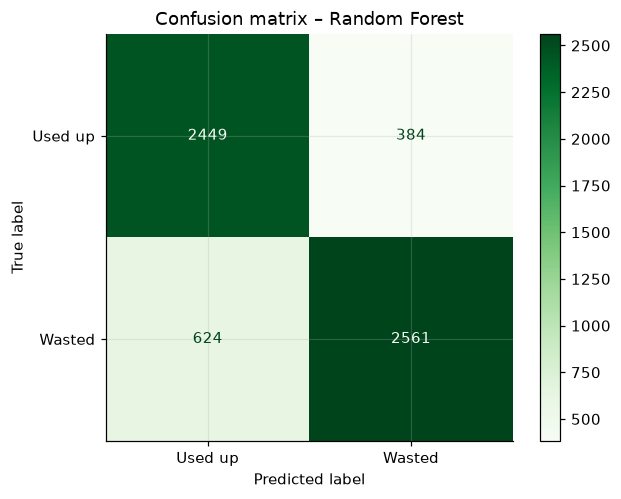

In [13]:
# STEP 4E: Apply the selection rule
best_auc = comparison["ROC-AUC"].max()
shortlist = comparison[comparison["ROC-AUC"] >= best_auc - 0.01].copy()
shortlist["explain_rank"] = shortlist["Explainable?"].str.startswith("Yes").astype(int)
best_row = shortlist.sort_values(["F1-score", "explain_rank"], ascending=False).iloc[0]
best_name = best_row.Model; best_model = models[best_name]
print("Shortlist:", list(shortlist.Model)); print(f"Selected: {best_name}  (ROC-AUC {best_row['ROC-AUC']:.3f}, F1 {best_row['F1-score']:.3f}, recall {best_row.Recall:.3f})")
ConfusionMatrixDisplay.from_predictions(y_test, (probs[best_name] >= .5).astype(int), display_labels=["Used up", "Wasted"], cmap="Greens")
plt.title(f"Confusion matrix – {best_name}"); plt.show()

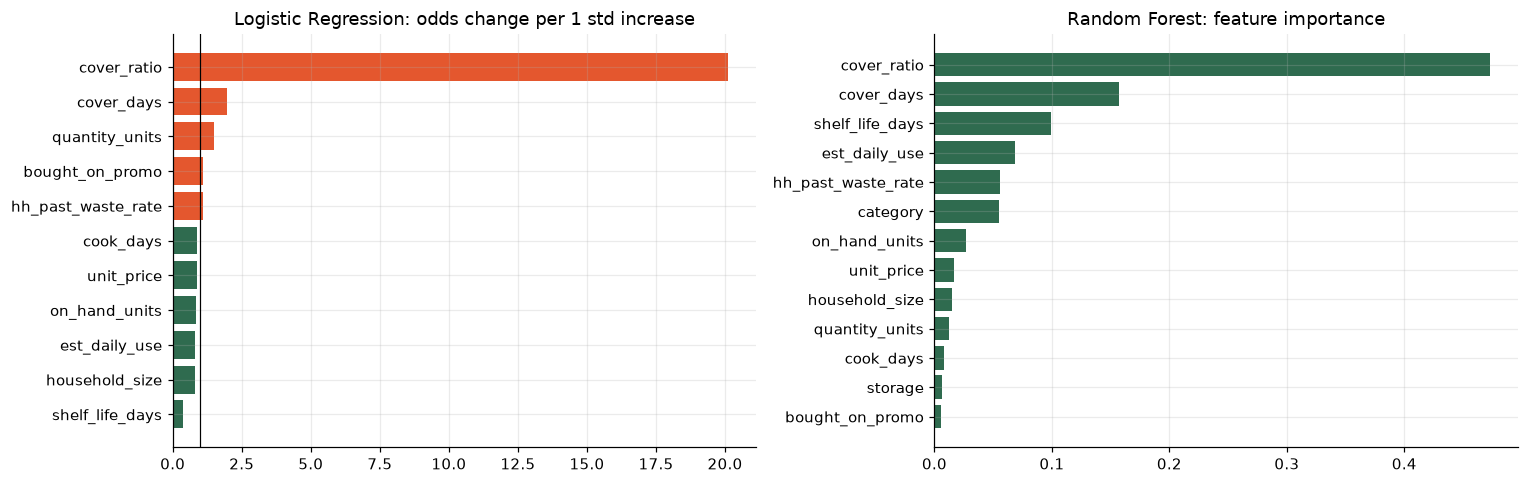

In [14]:
# STEP 4F: What drives waste? (explainability)
lr = models["Logistic Regression (balanced)"]
names = lr.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=names)
num = coef[[n for n in names if n.startswith("num__")]].rename(lambda n: n.replace("num__", ""))
odds = np.exp(num).sort_values()
rf = models["Random Forest"]
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=names).rename(lambda n: n.split("__")[1])
imp = imp.groupby(lambda n: "category" if n.startswith("category_") else ("storage" if n.startswith("storage_") else n)).sum().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].barh(odds.index, odds.values, color=[TOMATO if v > 1.05 else (GREEN if v < .95 else GREY) for v in odds.values]); ax[0].axvline(1, color="k", lw=.8)
ax[0].set_title("Logistic Regression: odds change per 1 std increase")
ax[1].barh(imp.index, imp.values, color=GREEN); ax[1].set_title("Random Forest: feature importance")
plt.tight_layout(); plt.show()

### From risk score to alerts – AI vs a simple date reminder
A **non-AI alternative** is a plain date reminder: notify the user about every item 2 days before it expires. The AI instead alerts only items whose waste risk is above a threshold.

**Alert fatigue** is the reason this matters: the more alerts people get, the fewer they act on. Assumptions (stated for the viva, change them in the cell):
* when a household acts on an alert, it saves **50%** of the waste that item would have caused;
* the chance a household acts on an alert falls as alerts pile up: **response = 60% ÷ (1 + 0.25 × alerts per week)** – about 40% at 2 alerts a week, about 21% at 7–8.

In [15]:
# STEP 4G: Choose the alert threshold
SAVE_SHARE, BASE_RESPONSE, FATIGUE = 0.50, 0.60, 0.25
p = probs[best_name]; wv = test.wasted_value.values; w = test.wasted.values
weeks_test, n_hh = 2, test.household_id.nunique()
def alert_policy(mask, label):
    per_week = mask.sum() / n_hh / weeks_test
    response = BASE_RESPONSE / (1 + FATIGUE * per_week)
    return {"Policy": label, "Alerts per household per week": per_week, "Useful alerts (%)": (w[mask == 1].mean() * 100) if mask.sum() else 0,
            "Waste covered by alerts (%)": (wv * mask).sum() / wv.sum() * 100, "Response rate (%)": response * 100,
            "Waste saved (₹)": (wv * mask).sum() * response * SAVE_SHARE}
rows = [alert_policy(np.ones_like(w), "Date reminder for every item (no AI)")]
for th in np.round(np.arange(0.3, 0.91, 0.1), 1):
    rows.append(alert_policy((p >= th).astype(int), f"AI alert if risk ≥ {th}"))
alerts = pd.DataFrame(rows)
best_alert = alerts.iloc[1:].sort_values("Waste saved (₹)").iloc[-1]
display(alerts.round(1))
gain = best_alert["Waste saved (₹)"] / alerts.iloc[0]["Waste saved (₹)"] - 1
print(f"Best: {best_alert.Policy} → {best_alert['Alerts per household per week']:.1f} alerts/household/week "
      f"(vs {alerts.iloc[0]['Alerts per household per week']:.1f}), {best_alert['Useful alerts (%)']:.0f}% useful (vs {alerts.iloc[0]['Useful alerts (%)']:.0f}%), "
      f"saves {gain:.0%} more food than date reminders")
ALERT_TH = float(best_alert.Policy.split("≥ ")[1])

,Policy,Alerts per household per week,Useful alerts (%),Waste covered by alerts (%),Response rate (%),Waste saved (₹)
0,Date reminder for every item (no AI),7.5,52.9,100.0,20.8,13707.0
1,AI alert if risk ≥ 0.3,4.6,79.2,91.1,28.1,16827.6
2,AI alert if risk ≥ 0.4,4.1,82.8,87.4,29.6,17006.4
3,AI alert if risk ≥ 0.5,3.7,87.0,83.2,31.2,17117.3
4,AI alert if risk ≥ 0.6,3.3,90.2,78.9,32.9,17107.8
5,AI alert if risk ≥ 0.7,2.8,94.0,71.8,35.5,16749.6
6,AI alert if risk ≥ 0.8,2.3,96.9,61.1,38.3,15421.2
7,AI alert if risk ≥ 0.9,1.6,98.8,45.6,43.1,12924.7


Best: AI alert if risk ≥ 0.5 → 3.7 alerts/household/week (vs 7.5), 87% useful (vs 53%), saves 25% more food than date reminders


In [16]:
# STEP 4H: Save Model 1
joblib.dump(best_model, "waste_risk_model.pkl", compress=3)
joblib.dump({"features": FEATURES, "threshold": ALERT_TH, "global_waste_rate": float(global_rate)}, "waste_risk_meta.pkl")
comparison.to_csv("waste_model_comparison.csv", index=False)
print("Saved waste_risk_model.pkl")

Saved waste_risk_model.pkl


## Step 5 – AI Model 2: How much will the household use next week?
**AI type:** supervised regression on time-series features (last 3 weeks, 4-week average, household size, festival week).
**Baselines:** last week's use, and the household's 4-week average. **Split:** train on weeks 5–9, test on weeks 10–12 (the weeks right after a festival, when habits snap back).

In [17]:
# STEP 5A: Weekly demand features
from sklearn.ensemble import RandomForestRegressor
weekly = pd.read_csv("data/weekly_demand.csv").sort_values(["household_id", "category", "week"])
g = weekly.groupby(["household_id", "category"]).demand_units
for k in [1, 2, 3]: weekly[f"lag_{k}"] = g.shift(k)
weekly["avg_4w"] = g.transform(lambda s: s.shift(1).rolling(4).mean())
weekly = weekly.merge(households[["household_id", "household_size"]], on="household_id")
weekly["festival_week"] = (weekly.week == 8).astype(int)                      # a festival in week 9
weekly["festival_in_last_4w"] = weekly.week.between(9, 12).astype(int)
weekly["normal_week_use"] = weekly.demand_units.where(weekly.week != 8)
weekly["avg_normal_weeks"] = weekly.groupby(["household_id", "category"]).normal_week_use.transform(lambda s: s.shift(1).expanding().mean())
weekly["cat_code"] = weekly.category.astype("category").cat.codes
F2 = ["lag_1", "lag_2", "lag_3", "avg_4w", "avg_normal_weeks", "festival_week", "festival_in_last_4w", "household_size", "cat_code"]
wk = weekly.dropna(subset=["avg_4w", "avg_normal_weeks"])
tr2, te2 = wk[wk.week <= 8], wk[wk.week >= 9].copy()
cons_model = RandomForestRegressor(n_estimators=300, max_depth=10, min_samples_leaf=20, random_state=42, n_jobs=-1).fit(tr2[F2], tr2.demand_units)
te2["rf"] = cons_model.predict(te2[F2]); te2["ma"] = te2.avg_4w; te2["last"] = te2.lag_1
def scores(col):
    e = te2[col] - te2.demand_units
    return {"MAE (units/week)": e.abs().mean(), "WAPE (%)": e.abs().sum() / te2.demand_units.sum() * 100, "Bias (%)": e.sum() / te2.demand_units.sum() * 100}
forecast_cmp = pd.DataFrame({"Last week's use": scores("last"), "4-week average (baseline)": scores("ma"), "Random Forest (AI)": scores("rf")}).T
display(forecast_cmp.round(2))
print("The 4-week average over-forecasts after the festival week (bias above); the AI model learns that festival weeks are one-offs.")

,MAE (units/week),WAPE (%),Bias (%)
Last week's use,0.35,25.47,9.52
4-week average (baseline),0.25,17.95,7.00
Random Forest (AI),0.22,16.01,1.11


The 4-week average over-forecasts after the festival week (bias above); the AI model learns that festival weeks are one-offs.


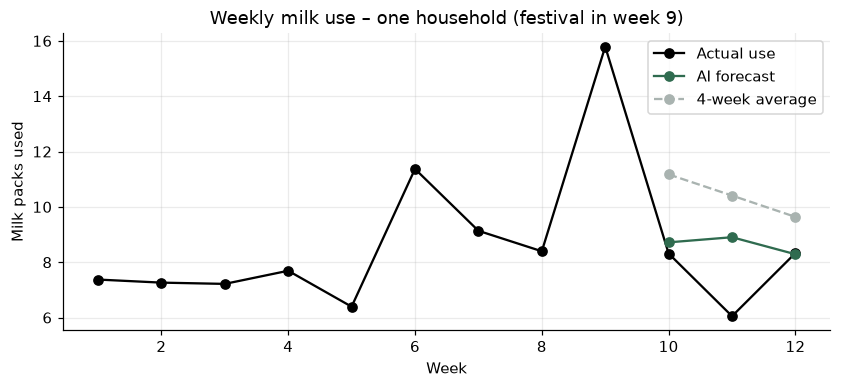

['consumption_features.pkl']

In [18]:
# STEP 5B: Example household
ex = weekly[(weekly.household_id == te2.household_id.iat[0]) & (weekly.category == "Milk")]
exf = te2[(te2.household_id == ex.household_id.iat[0]) & (te2.category == "Milk")]
plt.figure(figsize=(9, 3.5)); plt.plot(ex.week + 1, ex.demand_units, "o-", color="k", label="Actual use")
plt.plot(exf.week + 1, exf.rf, "o-", color=GREEN, label="AI forecast"); plt.plot(exf.week + 1, exf.ma, "o--", color=GREY, label="4-week average")
plt.xlabel("Week"); plt.ylabel("Milk packs used"); plt.legend(); plt.title("Weekly milk use – one household (festival in week 9)"); plt.show()
joblib.dump(cons_model, "consumption_model.pkl", compress=3); joblib.dump(F2, "consumption_features.pkl")

## Step 6 – Back-test: habitual shopping vs AI smart shopping list
We replay the real daily use of weeks 10–12 for every household and category, twice, from an empty pantry:
* **Habitual:** the household's own buying habit (over-buying, promotions, partly checking the fridge).
* **AI list:** buy next period's forecast use + a 10% buffer, minus what is already at home.

Both policies use the same shopping days and storage choices, so the only difference is **how much is bought**.

In [19]:
# STEP 6A: Replay
import zlib
daily = pd.read_csv("data/daily_demand_backtest.csv")
daily = daily[daily.day >= 63]
prefs = pd.read_csv("data/preferences.csv").set_index("household_id")
cat_info = categories.set_index("category")
fc = te2.set_index(["household_id", "category", "week"]).rf
H = households.set_index("household_id")

def replay(hid, cat, dem, policy, seed):
    rng = np.random.default_rng(seed)
    info, h = cat_info.loc[cat], H.loc[hid]
    shop = [int(x) for x in str(h.shop_days).split()]
    life_best = int(info.shelf_life_best)
    days = list(range(63, 84))
    my_days = [d for d in days if d % 2 == 1] if life_best <= 3 else [d for d in days if d % 7 in shop]
    pantry, bought, wasted, short = [], 0.0, 0.0, 0.0
    for t, d in enumerate(days):
        if d in my_days:
            nxt = next((s for s in my_days if s > d), d + 7); gap = min(nxt - d, life_best + 1)
            on_hand = sum(x[0] for x in pantry)
            u1, u2, u3 = rng.random(), rng.random(), rng.uniform(0.8, 1.25)
            if policy == "habit":
                want = h.household_size * info.rate * prefs.loc[hid, cat] * gap * h.overbuy * u3 - h.pantry_awareness * on_hand
                if u1 < 0.12: want *= 1.8
            else:
                f = fc.get((hid, cat, d // 7), np.nan)
                daily_f = f / 7 if f == f else h.household_size * info.rate * prefs.loc[hid, cat]
                want = daily_f * gap * 1.10 - on_hand
            qty = int(np.ceil(want)) if want > 0.25 else 0
            if qty:
                storage = info.best_storage if u2 < h.stores_correctly else info.worse_storage
                life = LIFE[cat].get(storage, LIFE[cat][info.best_storage])
                pantry.append([float(qty), d + life]); bought += qty
        need = dem[t]; pantry.sort(key=lambda x: x[1])
        for x in pantry:
            if need <= 0: break
            take = min(x[0], need); x[0] -= take; need -= take
        short += max(need, 0)
        keep = []
        for x in pantry:
            if x[1] <= d and x[0] > 1e-6: wasted += x[0]
            elif x[0] > 1e-6: keep.append(x)
        pantry = keep
    return bought, wasted, short

LIFE = {"Milk": {"fridge": 3, "pantry": 1}, "Curd": {"fridge": 6, "pantry": 2}, "Paneer": {"fridge": 4, "freezer": 30},
        "Bread": {"pantry": 4, "fridge": 6}, "Eggs": {"fridge": 18, "pantry": 7}, "Bananas": {"pantry": 4, "fridge": 6},
        "Apples": {"fridge": 20, "pantry": 8}, "Tomatoes": {"pantry": 5, "fridge": 9}, "Leafy greens": {"fridge": 3, "pantry": 1},
        "Coriander": {"fridge": 5, "pantry": 2}, "Onions": {"pantry": 30}, "Chicken": {"fridge": 2, "freezer": 60},
        "Cheese": {"fridge": 25}, "Snacks": {"pantry": 90}, "Rice & atta": {"pantry": 180}}
perishable = [c for c in categories.category if LIFE[c][cat_info.loc[c, "best_storage"]] <= 25]
res = []
for (hid, cat), g in daily[daily.category.isin(perishable)].groupby(["household_id", "category"]):
    dem = g.sort_values("day").demand_units.values
    seed = zlib.crc32(f"{hid}|{cat}".encode())
    for pol in ["habit", "ai"]:
        b, wst, sh = replay(hid, cat, dem, pol, seed)
        res.append({"household_id": hid, "category": cat, "policy": pol, "bought": b, "wasted": wst, "short": sh, "demand": dem.sum()})
bt = pd.DataFrame(res).merge(categories[["category", "price", "kg_per_unit"]], on="category")
bt["wasted_value"] = bt.wasted * bt.price; bt["wasted_kg"] = bt.wasted * bt.kg_per_unit; bt["spend"] = bt.bought * bt.price
summary = bt.groupby("policy").agg(spend=("spend", "sum"), wasted_value=("wasted_value", "sum"), wasted_kg=("wasted_kg", "sum"),
                                   short=("short", "sum"), demand=("demand", "sum")).T[["habit", "ai"]]
summary.loc["Demand met (%)"] = (1 - summary.loc["short"] / summary.loc["demand"]) * 100
summary.columns = ["Habitual shopping", "AI smart list"]
per_month = 30 / 21 / households.shape[0]
backtest = pd.DataFrame({
    "Food spend per household per month (₹)": summary.loc["spend"] * per_month,
    "Food wasted per household per month (₹)": summary.loc["wasted_value"] * per_month,
    "Food wasted per household per month (kg)": summary.loc["wasted_kg"] * per_month,
    "Demand met from the pantry (%)": summary.loc["Demand met (%)"],
}).T
backtest["Change"] = backtest["AI smart list"] - backtest["Habitual shopping"]
display(backtest.round(1))
backtest.to_csv("shopping_backtest.csv")

,Habitual shopping,AI smart list,Change
Food spend per household per month (₹),4774.4,4195.4,-579.0
Food wasted per household per month (₹),727.8,435.8,-292.0
Food wasted per household per month (kg),7.3,3.9,-3.4
Demand met from the pantry (%),87.0,85.7,-1.2


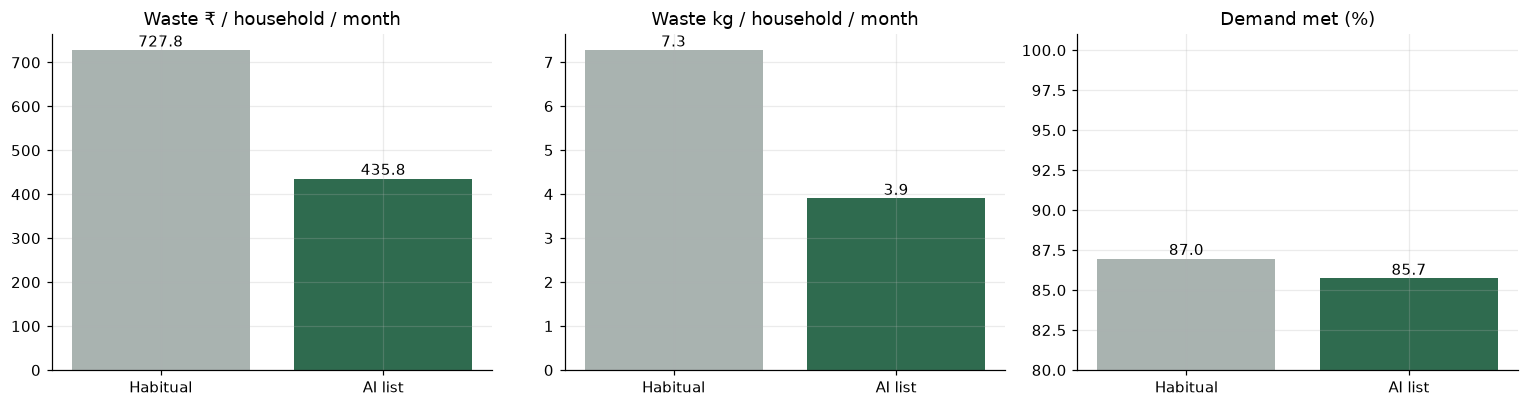

In [20]:
# STEP 6B: Picture of the result + savings per household for the app
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, row, t in zip(ax, ["Food wasted per household per month (₹)", "Food wasted per household per month (kg)", "Demand met from the pantry (%)"],
                     ["Waste ₹ / household / month", "Waste kg / household / month", "Demand met (%)"]):
    v = backtest.loc[row, ["Habitual shopping", "AI smart list"]]; bars = a.bar(["Habitual", "AI list"], v, color=[GREY, GREEN]); a.set_title(t)
    for b in bars: a.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.1f}", ha="center", va="bottom")
    if "Demand" in row: a.set_ylim(80, 101)
plt.tight_layout(); plt.show()
hh_bt = bt.pivot_table(index="household_id", columns="policy", values=["wasted_value", "wasted_kg", "spend"], aggfunc="sum") * (30 / 21)
hh_bt.columns = [f"{a}_{b}" for a, b in hh_bt.columns]
hh_bt.round(2).to_csv("data/household_backtest.csv")

## Step 7 – KPI summary

In [21]:
# STEP 7A: Business KPIs (saved for the app, report and slides)
CO2_PER_KG = 2.5   # kg CO2e per kg of food wasted – an approximate planning factor (assumption)
hab, ai = backtest["Habitual shopping"], backtest["AI smart list"]
kpis = {
    "households": int(len(households)), "weeks": 12,
    "share_spend_wasted_pct": round(float(headline.iloc[0]), 1),
    "waste_per_household_month_rs": round(float(headline.iloc[1])),
    "waste_per_person_month_kg": round(float(headline.iloc[2]), 2),
    "selected_model": best_name, "model_roc_auc": round(float(best_row["ROC-AUC"]), 3),
    "model_f1": round(float(best_row["F1-score"]), 3), "model_recall": round(float(best_row.Recall), 3),
    "model_precision": round(float(best_row.Precision), 3),
    "alert_threshold": ALERT_TH,
    "alerts_per_hh_week_ai": round(float(best_alert["Alerts per household per week"]), 1),
    "alert_saving_gain_pct": round(float(gain) * 100),
    "alerts_per_hh_week_dates": round(float(alerts.iloc[0]["Alerts per household per week"]), 1),
    "useful_alerts_ai_pct": round(float(best_alert["Useful alerts (%)"])),
    "useful_alerts_dates_pct": round(float(alerts.iloc[0]["Useful alerts (%)"])),
    "forecast_wape_baseline": round(float(forecast_cmp.iloc[1, 1]), 1), "forecast_wape_ai": round(float(forecast_cmp.iloc[2, 1]), 1),
    "waste_rs_month_habit": round(float(hab.iloc[1])), "waste_rs_month_ai": round(float(ai.iloc[1])),
    "waste_kg_month_habit": round(float(hab.iloc[2]), 2), "waste_kg_month_ai": round(float(ai.iloc[2]), 2),
    "spend_rs_month_habit": round(float(hab.iloc[0])), "spend_rs_month_ai": round(float(ai.iloc[0])),
    "demand_met_habit_pct": round(float(hab.iloc[3]), 1), "demand_met_ai_pct": round(float(ai.iloc[3]), 1),
    "co2_per_kg": CO2_PER_KG,
}
kpis["waste_cut_pct"] = round((1 - kpis["waste_rs_month_ai"] / kpis["waste_rs_month_habit"]) * 100)
kpis["co2_saved_kg_month"] = round((kpis["waste_kg_month_habit"] - kpis["waste_kg_month_ai"]) * CO2_PER_KG, 1)
json.dump(kpis, open("kpis.json", "w"), indent=2)
display(pd.Series(kpis).to_frame("Value"))

,Value
households,400
weeks,12
share_spend_wasted_pct,22.5
waste_per_household_month_rs,915
waste_per_person_month_kg,3.3
selected_model,Random Forest
model_roc_auc,0.922
model_f1,0.836
model_recall,0.804
model_precision,0.87


In [22]:
# STEP 7B: Files for the app – today's pantry with model features, household history
cur = pd.read_csv("data/current_pantry.csv").merge(households[["household_id", "household_size", "cook_days_per_week"]], on="household_id")
cur = cur.rename(columns={"cook_days_per_week": "cook_days"})
cur["cover_days"] = (cur.on_hand_units + cur.quantity_units) / cur.est_daily_use
cur["cover_ratio"] = cur.cover_days / cur.shelf_life_days
last = purchases[purchases.expiry_day >= 84 - 28].groupby("household_id").wasted.mean()
cur["hh_past_waste_rate"] = cur.household_id.map(last).fillna(global_rate)
cur = cur[cur.category != "Rice & atta"]
cur.to_csv("data/current_pantry_features.csv", index=False)
hist = purchases.groupby(["household_id", "week", "category"]).agg(wasted_value=("wasted_value", "sum"), wasted_kg=("wasted_kg", "sum"),
                                                                   value=("value", "sum")).reset_index()
hist.to_csv("data/household_waste_history.csv", index=False)
print("App files written:", len(cur), "pantry items;", len(hist), "history rows")

App files written: 5037 pantry items; 37038 history rows


## Step 8 – Responsible AI, privacy and limitations
* **Privacy (India – DPDP Act 2023):** pantry and shopping data reveal habits, diet and household size. Collect with consent, use only to reduce waste, keep data on the user's account, allow deletion. Partners get only aggregated, anonymous data.
* **Fairness & inclusion:** works for vegetarian and non-vegetarian homes and all household sizes; no protected attributes are used.
* **Honest nudges:** alerts are capped and ranked by risk – no guilt messaging; suggestions to *share or donate* surplus are optional.
* **Food safety:** expiry estimates are guidance, not a safety guarantee; the app always tells users to check smell, look and the printed date.
* **Limitations:** synthetic data; ₹ and CO₂ figures rest on stated assumptions (50% of waste saved when an alert is acted on, a response rate that falls with alert volume, 2.5 kg CO₂e per kg). A pilot with real households and an A/B test is needed. Real deployment would add receipt scanning (OCR) and barcode or photo recognition to log items automatically.

## Step 9 – Streamlit app
Saved as **app.py**. Run it from a terminal with `streamlit run app.py` (Streamlit cannot run inside a notebook cell).

In [23]:
%%writefile app.py
import json
import math
from pathlib import Path

import altair as alt
import joblib
import numpy as np
import pandas as pd
import streamlit as st

# ==================================================================
# Settings – rename the app here
# ==================================================================
APP_NAME = "FreshKeep AI"
TAGLINE = "AI Food Waste & Expiry Tracker"
TODAY = pd.Timestamp("2026-10-26")          # the simulated "today" (day 84 of the data)

st.set_page_config(page_title=f"{APP_NAME} – {TAGLINE}", page_icon="🥬", layout="wide")

try:
    BASE = Path(__file__).resolve().parent
except NameError:
    BASE = Path.cwd()

LEAF, MINT, TOMATO, AMBER, INK, MUTED = "#1F5C45", "#E6F2EC", "#E4572E", "#F2A541", "#17302A", "#5E716B"

st.markdown(f"""
<style>
@import url('https://fonts.googleapis.com/css2?family=Plus+Jakarta+Sans:wght@400;500;600;700;800&display=swap');
html, body, [class*="css"], .stMarkdown, .stText, button, input, textarea {{ font-family: 'Plus Jakarta Sans', system-ui, sans-serif; }}
[data-testid="stHeader"] {{ background: transparent; }}
[data-testid="stToolbar"] {{ visibility: hidden; }}
.block-container {{ padding-top: 1.4rem; max-width: 1250px; }}
h1, h2, h3, h4 {{ color: {INK}; letter-spacing: -0.01em; }}
.hero {{ background: {LEAF}; color: white; border-radius: 22px; padding: 28px 32px; display: flex; justify-content: space-between;
        align-items: center; gap: 24px; flex-wrap: wrap; margin-bottom: 8px; }}
.hero h1 {{ color: white; font-size: 2.3rem; font-weight: 800; margin: 0; }}
.hero .tag {{ color: #BFE3D0; font-size: 1.02rem; font-weight: 600; margin-top: 2px; }}
.hero .sub {{ color: #E6F2EC; font-size: 0.98rem; margin-top: 10px; max-width: 640px; }}
.hero .pill {{ background: rgba(255,255,255,0.12); border: 1px solid rgba(255,255,255,0.25); border-radius: 999px; padding: 8px 16px;
              font-weight: 600; font-size: 0.92rem; white-space: nowrap; }}
.kpi {{ background: white; border: 1px solid #E3ECE7; border-radius: 18px; padding: 18px 20px; height: 100%; min-height: 132px;
       box-shadow: 0 1px 2px rgba(23,48,42,0.04); }}
.kpi .label {{ color: {MUTED}; font-size: 0.84rem; font-weight: 600; text-transform: uppercase; letter-spacing: 0.04em; }}
.kpi .value {{ color: {INK}; font-size: 2rem; font-weight: 800; line-height: 1.2; margin-top: 4px; }}
.kpi .note {{ color: {MUTED}; font-size: 0.86rem; margin-top: 2px; }}
.kpi.alert .value {{ color: {TOMATO}; }}
.kpi.good .value {{ color: {LEAF}; }}
.item {{ background: white; border: 1px solid #E3ECE7; border-radius: 18px; padding: 16px 18px; margin-bottom: 14px; }}
.item .top {{ display: flex; justify-content: space-between; align-items: center; gap: 8px; }}
.item .name {{ font-weight: 700; color: {INK}; font-size: 1.05rem; }}
.item .meta {{ color: {MUTED}; font-size: 0.86rem; margin-top: 6px; }}
.item .tip {{ color: {INK}; font-size: 0.9rem; margin-top: 10px; background: {MINT}; border-radius: 10px; padding: 8px 10px; }}
.chip {{ border-radius: 999px; padding: 3px 10px; font-size: 0.78rem; font-weight: 700; white-space: nowrap; }}
.chip.red {{ background: #FDE5DE; color: #B23A1B; }}
.chip.amber {{ background: #FDF0DA; color: #8A5A00; }}
.chip.green {{ background: {MINT}; color: {LEAF}; }}
.bar {{ height: 8px; background: #EEF3F0; border-radius: 99px; margin-top: 10px; overflow: hidden; }}
.bar > div {{ height: 100%; border-radius: 99px; }}
.recipe {{ background: white; border: 1px solid #E3ECE7; border-radius: 18px; padding: 18px 20px; margin-bottom: 14px; }}
.recipe .title {{ font-weight: 800; font-size: 1.1rem; color: {INK}; }}
.recipe .uses {{ margin-top: 8px; display: flex; flex-wrap: wrap; gap: 6px; }}
.recipe .steps {{ color: {MUTED}; font-size: 0.9rem; margin-top: 10px; }}
.section-note {{ color: {MUTED}; font-size: 0.95rem; margin-top: -6px; margin-bottom: 14px; }}
.big {{ font-size: 2.6rem; font-weight: 800; color: {LEAF}; line-height: 1.1; }}
div[data-baseweb="tab-list"] {{ gap: 6px; }}
button[data-baseweb="tab"] {{ font-weight: 600; }}
</style>
""", unsafe_allow_html=True)

# ==================================================================
# Data and models
# ==================================================================
NEEDED = ["waste_risk_model.pkl", "waste_risk_meta.pkl", "consumption_model.pkl", "consumption_features.pkl", "kpis.json",
          "waste_model_comparison.csv", "data/households.csv", "data/categories.csv", "data/current_pantry_features.csv",
          "data/household_waste_history.csv", "data/weekly_demand.csv", "data/household_backtest.csv"]
missing = [f for f in NEEDED if not (BASE / f).exists()]
if missing:
    st.error("Missing project files: " + ", ".join(missing) + ". Run FoodWaste_Expiry_Tracker.ipynb first.")
    st.stop()


@st.cache_resource
def load_models():
    return (joblib.load(BASE / "waste_risk_model.pkl"), joblib.load(BASE / "waste_risk_meta.pkl"),
            joblib.load(BASE / "consumption_model.pkl"), joblib.load(BASE / "consumption_features.pkl"))


@st.cache_data
def load_data():
    d = BASE / "data"
    return (pd.read_csv(d / "households.csv"), pd.read_csv(d / "categories.csv"), pd.read_csv(d / "current_pantry_features.csv"),
            pd.read_csv(d / "household_waste_history.csv"), pd.read_csv(d / "weekly_demand.csv"),
            pd.read_csv(d / "household_backtest.csv"), json.load(open(BASE / "kpis.json")),
            pd.read_csv(BASE / "waste_model_comparison.csv"))


risk_model, meta, cons_model, cons_feats = load_models()
households, cats, pantry_all, history, weekly, hh_bt, K, model_cmp = load_data()
FEATURES, ALERT_TH = meta["features"], meta["threshold"]
CAT = cats.set_index("category")

LIFE = {"Milk": {"fridge": 3, "pantry": 1}, "Curd": {"fridge": 6, "pantry": 2}, "Paneer": {"fridge": 4, "freezer": 30},
        "Bread": {"pantry": 4, "fridge": 6}, "Eggs": {"fridge": 18, "pantry": 7}, "Bananas": {"pantry": 4, "fridge": 6},
        "Apples": {"fridge": 20, "pantry": 8}, "Tomatoes": {"pantry": 5, "fridge": 9}, "Leafy greens": {"fridge": 3, "pantry": 1},
        "Coriander": {"fridge": 5, "pantry": 2}, "Onions": {"pantry": 30}, "Chicken": {"fridge": 2, "freezer": 60},
        "Cheese": {"fridge": 25}, "Snacks": {"pantry": 90}}
EMOJI = {"Milk": "🥛", "Curd": "🥣", "Paneer": "🧀", "Bread": "🍞", "Eggs": "🥚", "Bananas": "🍌", "Apples": "🍎", "Tomatoes": "🍅",
         "Leafy greens": "🥬", "Coriander": "🌿", "Onions": "🧅", "Chicken": "🍗", "Cheese": "🧀", "Snacks": "🍪"}
TIPS = {"Milk": "Boil it, or turn it into paneer or kheer before it turns.", "Curd": "Make lassi, raita or curd rice today.",
        "Paneer": "Freeze it in cubes – it keeps for weeks.", "Bread": "Toast it or make bread upma; keep loaves in the fridge.",
        "Eggs": "Keep them in the fridge, not on the counter.", "Bananas": "Very ripe? Banana shake, or peel and freeze.",
        "Apples": "Store in the fridge crisper – they last twice as long.", "Tomatoes": "Cook a quick tomato chutney; move the rest to the fridge.",
        "Leafy greens": "Cook palak dal today – greens wilt fast.", "Coriander": "Wrap in a damp cloth in the fridge, or blend into chutney.",
        "Onions": "Keep in a dry, airy basket.", "Chicken": "Cook today or move it to the freezer.", "Cheese": "Wrap tightly after opening.",
        "Snacks": "Close the pack with a clip."}
RECIPES = [
    ("Bread upma", ["Bread", "Onions", "Tomatoes", "Coriander"], 15, "Cube the bread, sauté onion and tomato with mustard seeds and curry leaves, toss the bread in, finish with coriander."),
    ("French toast", ["Bread", "Eggs", "Milk"], 10, "Whisk eggs with milk and a pinch of salt or sugar, dip the slices, pan-fry until golden."),
    ("Banana milkshake", ["Bananas", "Milk"], 5, "Blend ripe bananas with chilled milk and a little honey."),
    ("Palak dal", ["Leafy greens", "Onions", "Tomatoes"], 30, "Cook dal, add chopped spinach, finish with a tempering of garlic, cumin and onion."),
    ("Paneer bhurji", ["Paneer", "Onions", "Tomatoes", "Coriander"], 15, "Crumble paneer into sautéed onion and tomato with turmeric and garam masala."),
    ("Masala omelette", ["Eggs", "Onions", "Tomatoes", "Coriander"], 10, "Beat eggs with chopped onion, tomato and coriander, cook in a hot pan."),
    ("Curd rice", ["Curd", "Milk"], 10, "Mix cooked rice with curd and a splash of milk, temper with mustard seeds and curry leaves."),
    ("Sweet lassi", ["Curd", "Milk"], 5, "Blend curd with a little milk, sugar and cardamom."),
    ("Rice kheer", ["Milk"], 40, "Simmer milk with a handful of rice until creamy, add sugar, cardamom and nuts."),
    ("Tomato chutney", ["Tomatoes", "Onions", "Coriander"], 20, "Cook tomatoes and onion until soft, blend with chilli and salt, temper with mustard seeds."),
    ("Fruit chaat", ["Apples", "Bananas"], 10, "Chop the fruit, toss with chaat masala and lemon juice."),
    ("Chicken curry", ["Chicken", "Onions", "Tomatoes", "Coriander"], 45, "Brown onion, cook tomato and spices into a masala, simmer the chicken until done."),
    ("Cheese toast", ["Bread", "Cheese", "Tomatoes"], 10, "Top bread with tomato slices and cheese, toast until bubbling."),
    ("Raita", ["Curd", "Onions", "Coriander"], 5, "Whisk curd with chopped onion, coriander, roasted cumin and salt."),
    ("Green chutney", ["Coriander", "Leafy greens"], 10, "Blend coriander and spinach with chilli, lemon and salt."),
    ("Apple shake", ["Apples", "Milk"], 5, "Blend chopped apples with cold milk and a pinch of cinnamon."),
]


def score_pantry(df):
    df = df.copy()
    df["risk"] = risk_model.predict_proba(df[FEATURES])[:, 1]
    df["value_left"] = df.remaining_units * df.unit_price
    df["at_risk_value"] = df.value_left * df.risk
    df["need_days"] = df.remaining_units / df.est_daily_use.clip(lower=0.01)
    df["expiry_date"] = [TODAY + pd.Timedelta(days=int(x)) for x in df.days_left]
    return df


@st.cache_data
def household_options():
    sc = score_pantry(pantry_all)
    hot = sc[sc.risk >= ALERT_TH].groupby("household_id").size()
    h = households.set_index("household_id")
    labels = {}
    for hid in h.index:
        r = h.loc[hid]
        diet = "veg" if r.vegetarian else "non-veg"
        labels[hid] = f"{r.household_type} of {r.household_size} · {diet} · {hid}" if r.household_size > 1 else f"Single · {diet} · {hid}"
    bt = hh_bt.set_index("household_id")
    gain = (bt.wasted_value_habit - bt.wasted_value_ai)
    pool = [x for x in hot[hot >= 5].index if h.loc[x, "household_size"] in (3, 4) and x in gain.index]
    target = gain.quantile(0.6)
    default = min(pool, key=lambda x: abs(gain[x] - target)) if pool else hot.idxmax()
    return labels, default


labels, default_hh = household_options()

# ==================================================================
# Sidebar – choose a demo household
# ==================================================================
with st.sidebar:
    st.markdown(f"### 🥬 {APP_NAME}")
    st.caption(TAGLINE)
    ids = list(labels)
    hid = st.selectbox("Demo household", ids, index=ids.index(default_hh), format_func=lambda x: labels[x])
    H = households.set_index("household_id").loc[hid]
    st.markdown(f"""
**Household profile**
- 👥 {H.household_size} people · {'vegetarian' if H.vegetarian else 'non-vegetarian'}
- 🛒 Shops {H.shops_per_week}× a week
- 🍳 Cooks at home {H.cook_days_per_week} days a week
""")
    st.caption(f"Today: {TODAY:%d %b %Y}. All households and data are simulated.")

if "used" not in st.session_state: st.session_state.used = set()
if "added" not in st.session_state: st.session_state.added = []

pantry = pantry_all[pantry_all.household_id == hid].copy()
pantry["item_key"] = [f"{hid}-{i}" for i in pantry.index]
if st.session_state.added:
    extra = pd.DataFrame([a for a in st.session_state.added if a["household_id"] == hid])
    if len(extra): pantry = pd.concat([pantry, extra], ignore_index=True)
pantry = pantry[~pantry.item_key.isin(st.session_state.used)]
pantry = score_pantry(pantry) if len(pantry) else pantry
past_rate = float(pantry_all.loc[pantry_all.household_id == hid, "hh_past_waste_rate"].iloc[0]) if (pantry_all.household_id == hid).any() else meta["global_waste_rate"]


def status(days, risk):
    if days <= 1 or risk >= 0.75: return "red", "Use today" if days <= 1 else "High risk"
    if days <= 3 or risk >= ALERT_TH: return "amber", "Use soon"
    return "green", "Fresh"


def fmt_qty(cat, units):
    return f"{units:.1f} × {CAT.loc[cat, 'unit']}" if units % 1 else f"{int(units)} × {CAT.loc[cat, 'unit']}"


def item_card(r):
    colour, label = status(r.days_left, r.risk)
    bar_col = {"red": TOMATO, "amber": AMBER, "green": LEAF}[colour]
    return f"""
<div class="item">
  <div class="top"><div class="name">{EMOJI.get(r.category, '🥫')} {r.category}</div><span class="chip {colour}">{label}</span></div>
  <div class="meta">{fmt_qty(r.category, r.remaining_units)} left · expires {r.expiry_date:%a %d %b} ({int(r.days_left)} day{'s' if r.days_left != 1 else ''}) · {r.storage}</div>
  <div class="meta">AI waste risk <b>{r.risk:.0%}</b> · ₹{r.value_left:,.0f} of food</div>
  <div class="bar"><div style="width:{r.risk * 100:.0f}%; background:{bar_col}"></div></div>
  <div class="tip">💡 {TIPS.get(r.category, '')}</div>
</div>"""


def kpi(label, value, note="", kind=""):
    return f'<div class="kpi {kind}"><div class="label">{label}</div><div class="value">{value}</div><div class="note">{note}</div></div>'


# ==================================================================
# Hero
# ==================================================================
soon = pantry[(pantry.days_left <= 2)] if len(pantry) else pantry
risky = pantry[pantry.risk >= ALERT_TH] if len(pantry) else pantry
bt = hh_bt.set_index("household_id").loc[hid] if hid in set(hh_bt.household_id) else None
save_month = (bt.wasted_value_habit - bt.wasted_value_ai) if bt is not None else K["waste_rs_month_habit"] - K["waste_rs_month_ai"]
st.markdown(f"""
<div class="hero">
  <div>
    <h1>🥬 {APP_NAME}</h1>
    <div class="tag">{TAGLINE}</div>
    <div class="sub">Knows what is in your kitchen, warns you before food goes to waste, suggests what to cook,
    and tells you how much to buy next time.</div>
  </div>
  <div style="display:flex; flex-direction:column; gap:10px; align-items:flex-end">
    <span class="pill">🔔 {len(risky)} item{'s' if len(risky) != 1 else ''} need attention</span>
    <span class="pill">💰 Save about ₹{save_month:,.0f} a month</span>
  </div>
</div>
""", unsafe_allow_html=True)

home, pan, cook, shop, impact, about = st.tabs(["🏠 Home", "🧺 My Pantry", "🍳 Use It Up", "🛒 Smart List", "🌱 Impact", "ℹ️ About"])

# ==================================================================
# Home
# ==================================================================
with home:
    c1, c2, c3, c4 = st.columns(4)
    at_risk_rs = pantry.at_risk_value.sum() if len(pantry) else 0
    co2 = ((bt.wasted_kg_habit - bt.wasted_kg_ai) if bt is not None else 3.4) * K["co2_per_kg"]
    c1.markdown(kpi("Use within 2 days", f"{len(soon)}", "items expiring soon", "alert" if len(soon) else ""), unsafe_allow_html=True)
    c2.markdown(kpi("Food at risk", f"₹{at_risk_rs:,.0f}", "expected waste if nothing changes", "alert"), unsafe_allow_html=True)
    c3.markdown(kpi("Monthly saving", f"₹{save_month:,.0f}", "with AI alerts + smart list", "good"), unsafe_allow_html=True)
    c4.markdown(kpi("CO₂ avoided", f"{co2:,.1f} kg", "per month, estimated", "good"), unsafe_allow_html=True)

    st.markdown("#### Use these first")
    st.markdown('<div class="section-note">Ranked by the AI: the chance each item ends up in the bin, weighted by its value.</div>', unsafe_allow_html=True)
    if len(pantry):
        top = pantry.sort_values(["at_risk_value"], ascending=False).head(6)
        cols = st.columns(3)
        for k, (_, r) in enumerate(top.iterrows()):
            cols[k % 3].markdown(item_card(r), unsafe_allow_html=True)
    else:
        st.success("Your pantry is empty – nothing to rescue today.")

    st.markdown("#### Where your money was wasted (last 12 weeks)")
    h = history[history.household_id == hid].groupby("category", as_index=False).wasted_value.sum()
    h = h[h.wasted_value > 0].sort_values("wasted_value", ascending=False)
    if len(h):
        chart = alt.Chart(h).mark_bar(cornerRadiusEnd=6, color=LEAF, size=18).encode(
            x=alt.X("wasted_value:Q", title="₹ wasted"), y=alt.Y("category:N", sort="-x", title=None),
            tooltip=[alt.Tooltip("category:N"), alt.Tooltip("wasted_value:Q", format=",.0f", title="₹ wasted")]).properties(height=34 * len(h))
        st.altair_chart(chart, width="stretch")

# ==================================================================
# My Pantry
# ==================================================================
with pan:
    st.markdown("#### Everything in your kitchen")
    st.markdown('<div class="section-note">Sorted by urgency. Tick items you have used and press the button to remove them.</div>', unsafe_allow_html=True)
    if len(pantry):
        show = pantry.sort_values(["days_left", "risk"], ascending=[True, False])
        table = pd.DataFrame({
            "Item": [f"{EMOJI.get(c, '🥫')} {c}" for c in show.category],
            "Left": [fmt_qty(c, u) for c, u in zip(show.category, show.remaining_units)],
            "Stored in": show.storage.str.title(),
            "Expires": [f"{d:%a %d %b}" for d in show.expiry_date],
            "Days left": show.days_left.astype(int),
            "AI waste risk": (show.risk * 100).round(0),
            "Status": [("🔴 " if s == "red" else "🟠 " if s == "amber" else "🟢 ") + l for s, l in (status(d, r) for d, r in zip(show.days_left, show.risk))],
            "Value (₹)": show.value_left.round(0),
        })
        st.dataframe(table, hide_index=True, width="stretch",
                     column_config={"AI waste risk": st.column_config.ProgressColumn("AI waste risk", min_value=0, max_value=100, format="%d%%"),
                                    "Value (₹)": st.column_config.NumberColumn(format="₹%d")})
        used = st.multiselect("Mark items as used", options=list(show.item_key),
                              format_func=lambda k: (lambda r: f"{r.category} – {fmt_qty(r.category, r.remaining_units)} (expires {r.expiry_date:%d %b})")(show.set_index('item_key').loc[k]))
        if st.button("✅ Remove used items", disabled=not used):
            st.session_state.used.update(used); st.rerun()

    st.markdown("#### Add something you just bought")
    with st.form("add_item"):
        a1, a2, a3, a4 = st.columns(4)
        new_cat = a1.selectbox("Item", list(LIFE), index=list(LIFE).index("Milk"))
        new_qty = a2.number_input(f"How many packs", min_value=1, max_value=20, value=2)
        new_store = a3.selectbox("Where will you keep it?", ["fridge", "pantry", "freezer"])
        new_promo = a4.checkbox("Bought on offer / bulk deal")
        go = st.form_submit_button("🔍 Check waste risk")
    if go:
        store = new_store if new_store in LIFE[new_cat] else max(LIFE[new_cat], key=LIFE[new_cat].get)
        life = LIFE[new_cat][store]
        w = weekly[(weekly.household_id == hid) & (weekly.category == new_cat)]
        daily_use = (w.demand_units.tail(4).mean() / 7) if len(w) else H.household_size * CAT.loc[new_cat, "rate"]
        on_hand = pantry.loc[pantry.category == new_cat, "remaining_units"].sum() if len(pantry) else 0
        row = {"category": new_cat, "storage": store, "shelf_life_days": life, "quantity_units": new_qty, "unit_price": CAT.loc[new_cat, "price"],
               "bought_on_promo": int(new_promo), "on_hand_units": on_hand, "est_daily_use": max(daily_use, 0.01),
               "household_size": H.household_size, "cook_days": H.cook_days_per_week, "hh_past_waste_rate": past_rate}
        row["cover_days"] = (on_hand + new_qty) / row["est_daily_use"]; row["cover_ratio"] = row["cover_days"] / life
        risk = float(risk_model.predict_proba(pd.DataFrame([row])[FEATURES])[0, 1])
        need = (on_hand + new_qty) / row["est_daily_use"]
        colour, label = status(life, risk)
        m1, m2, m3 = st.columns(3)
        m1.markdown(kpi("Expires", f"{(TODAY + pd.Timedelta(days=life)):%d %b}", f"{life} days in the {store}"), unsafe_allow_html=True)
        m2.markdown(kpi("AI waste risk", f"{risk:.0%}", label, "alert" if colour != "green" else "good"), unsafe_allow_html=True)
        m3.markdown(kpi("Time to finish", f"{need:.0f} days", f"at your usual pace, incl. {on_hand:.1f} already at home"), unsafe_allow_html=True)
        better = [s for s, d in LIFE[new_cat].items() if d > life]
        if risk >= ALERT_TH:
            fewer = max(1, math.floor(life * row["est_daily_use"] - on_hand))
            st.warning(f"This is likely to be wasted. You usually finish about **{life * row['est_daily_use']:.1f} packs** in {life} days"
                       + (f" – buying **{fewer}** would be enough." if fewer < new_qty else ".")
                       + (f" Storing it in the **{better[0]}** keeps it for {LIFE[new_cat][better[0]]} days." if better else ""))
        else:
            st.success("Looks fine – you are likely to use this up before it expires.")
        st.session_state.added.append({**row, "household_id": hid, "remaining_units": float(new_qty), "days_left": life,
                                       "day": 84, "item_key": f"{hid}-new-{len(st.session_state.added)}"})

# ==================================================================
# Use It Up – recipes
# ==================================================================
with cook:
    st.markdown("#### Cook these to rescue your food")
    st.markdown('<div class="section-note">Recipes ranked by how much at-risk food they use up.</div>', unsafe_allow_html=True)
    if len(pantry):
        risk_by_cat = pantry.groupby("category").at_risk_value.sum()
        have = set(pantry.category)
        ranked = []
        for name, ing, mins, steps in RECIPES:
            uses = [i for i in ing if i in have]
            if not uses: continue
            ranked.append((sum(risk_by_cat.get(i, 0) for i in uses), len(uses) / len(ing), name, ing, mins, steps, uses))
        ranked.sort(reverse=True)
        cols = st.columns(2)
        for k, (rescue, share, name, ing, mins, steps, uses) in enumerate(ranked[:8]):
            chips = "".join(
                f'<span class="chip {"red" if risk_by_cat.get(i, 0) > 20 else "green"}">{EMOJI.get(i, "")} {i}</span>' if i in uses
                else f'<span class="chip" style="background:#F1F3F2;color:#8A9893">+ {i}</span>' for i in ing)
            cols[k % 2].markdown(f"""
<div class="recipe">
  <div class="top" style="display:flex;justify-content:space-between"><div class="title">🍳 {name}</div><span class="chip green">⏱ {mins} min</span></div>
  <div class="meta" style="color:{MUTED};font-size:.88rem;margin-top:4px">Rescues about ₹{rescue:,.0f} of food · you have {len(uses)} of {len(ing)} ingredients</div>
  <div class="uses">{chips}</div>
  <div class="steps">{steps}</div>
</div>""", unsafe_allow_html=True)
    st.caption("Red = an item the AI expects you to waste. Grey = something you would need to add.")

# ==================================================================
# Smart List – Model 2
# ==================================================================
with shop:
    st.markdown("#### Next week's smart shopping list")
    st.markdown('<div class="section-note">The AI forecasts how much your household will actually use next week, then subtracts what is already at home.</div>', unsafe_allow_html=True)
    w = weekly[weekly.household_id == hid].sort_values(["category", "week"])
    rows = []
    for cat_name, g in w.groupby("category"):
        if cat_name == "Rice & atta" or len(g) < 5: continue
        s = g.demand_units.values
        normal = g.loc[g.week != 8, "demand_units"].mean()
        x = pd.DataFrame([{"lag_1": s[-1], "lag_2": s[-2], "lag_3": s[-3], "avg_4w": s[-4:].mean(), "avg_normal_weeks": normal,
                           "festival_week": 0, "festival_in_last_4w": 1, "household_size": H.household_size,
                           "cat_code": sorted(weekly.category.unique()).index(cat_name)}])[cons_feats]
        f = max(0.0, float(cons_model.predict(x)[0]))
        on_hand = pantry.loc[pantry.category == cat_name, "remaining_units"].sum() if len(pantry) else 0
        buy = max(0, math.ceil(f * 1.10 - on_hand - 0.25))
        hist = history[(history.household_id == hid) & (history.category == cat_name)]
        usual = hist.value.sum() / CAT.loc[cat_name, "price"] / 12
        life = LIFE[cat_name][CAT.loc[cat_name, "best_storage"]]
        rows.append({"Item": f"{EMOJI.get(cat_name, '')} {cat_name}", "Pack": CAT.loc[cat_name, "unit"], "Forecast use": round(f, 1),
                     "At home": round(on_hand, 1), "Buy": buy, "You usually buy": round(usual, 1),
                     "Tip": "Split into 2 trips" if life <= 4 and buy >= 2 else ("Nothing needed" if buy == 0 else ""),
                     "_saving": max(0, usual - buy) * CAT.loc[cat_name, "price"], "_cat": cat_name})
    sl = pd.DataFrame(rows)
    if len(sl):
        s1, s2, s3 = st.columns(3)
        s1.markdown(kpi("Items to buy", f"{(sl.Buy > 0).sum()}", f"{int(sl.Buy.sum())} packs in total"), unsafe_allow_html=True)
        s2.markdown(kpi("Less than usual", f"{max(0, sl['You usually buy'].sum() - sl.Buy.sum()):.0f} packs", "this week"), unsafe_allow_html=True)
        s3.markdown(kpi("Saved this week", f"₹{sl._saving.sum():,.0f}", "vs your usual weekly basket – partly because you already have enough at home", "good"), unsafe_allow_html=True)
        st.dataframe(sl.drop(columns=["_saving", "_cat"]).sort_values("Buy", ascending=False), hide_index=True, width="stretch",
                     column_config={"Buy": st.column_config.NumberColumn("Buy (packs)", format="%d"),
                                    "Forecast use": st.column_config.NumberColumn("Forecast use (packs)")})
        long = sl.melt(id_vars=["_cat"], value_vars=["You usually buy", "Buy"], var_name="Basket", value_name="Packs")
        long["Basket"] = long.Basket.replace({"Buy": "AI smart list"})
        st.altair_chart(alt.Chart(long).mark_bar(cornerRadiusEnd=4).encode(
            y=alt.Y("_cat:N", title=None), x=alt.X("Packs:Q", title="Packs"), yOffset=alt.YOffset("Basket:N"),
            color=alt.Color("Basket:N", scale=alt.Scale(range=["#A9B3B0", LEAF]), legend=alt.Legend(orient="top", title=None)),
            tooltip=[alt.Tooltip("_cat:N", title="Item"), "Basket", "Packs"]).properties(height=40 * len(sl)), width="stretch")

# ==================================================================
# Impact
# ==================================================================
with impact:
    st.markdown("#### What the AI achieves")
    st.markdown(f'<div class="section-note">Back-test: the last 3 weeks of all {K["households"]} simulated households replayed with their usual shopping habit, and again with the AI smart list.</div>', unsafe_allow_html=True)
    i1, i2, i3, i4 = st.columns(4)
    i1.markdown(kpi("Food waste cut", f"{K['waste_cut_pct']}%", f"₹{K['waste_rs_month_habit']} → ₹{K['waste_rs_month_ai']} per home per month", "good"), unsafe_allow_html=True)
    i2.markdown(kpi("Less food binned", f"{K['waste_kg_month_habit'] - K['waste_kg_month_ai']:.1f} kg", f"{K['waste_kg_month_habit']} → {K['waste_kg_month_ai']} kg per home per month", "good"), unsafe_allow_html=True)
    i3.markdown(kpi("Grocery spend", f"−₹{K['spend_rs_month_habit'] - K['spend_rs_month_ai']}", "per home per month", "good"), unsafe_allow_html=True)
    i4.markdown(kpi("Smarter alerts", f"{K['alerts_per_hh_week_ai']}/week", f"{K['useful_alerts_ai_pct']}% useful vs {K['useful_alerts_dates_pct']}% for date reminders"), unsafe_allow_html=True)

    st.markdown("#### If more homes used it")
    homes = st.slider("Households using the app", 1_000, 1_000_000, 100_000, step=1_000, format="%d")
    saved_rs = (K["waste_rs_month_habit"] - K["waste_rs_month_ai"]) * 12 * homes
    saved_t = (K["waste_kg_month_habit"] - K["waste_kg_month_ai"]) * 12 * homes / 1000
    j1, j2, j3 = st.columns(3)
    j1.markdown(kpi("Money saved a year", f"₹{saved_rs / 1e7:,.1f} crore", "by households", "good"), unsafe_allow_html=True)
    j2.markdown(kpi("Food saved a year", f"{saved_t:,.0f} tonnes", "kept out of the bin", "good"), unsafe_allow_html=True)
    j3.markdown(kpi("CO₂e avoided a year", f"{saved_t * K['co2_per_kg']:,.0f} tonnes", f"at {K['co2_per_kg']} kg CO₂e per kg of food", "good"), unsafe_allow_html=True)

    with st.expander("How the AI models perform"):
        st.markdown(f"**Model 1 – Will this item be wasted?** Four models compared on the last two weeks of purchases. "
                    f"Selected: **{K['selected_model']}** (ROC-AUC {K['model_roc_auc']}, catches {K['model_recall']:.0%} of wasted items, "
                    f"{K['model_precision']:.0%} of its alerts are right).")
        st.dataframe(model_cmp.round(3), hide_index=True, width="stretch")
        st.markdown(f"**Model 2 – How much will we use next week?** Random Forest forecast error {K['forecast_wape_ai']}% "
                    f"vs {K['forecast_wape_baseline']}% for a 4-week average.")
        st.caption("Selection rule: keep models within 0.01 ROC-AUC of the best, pick the highest F1-score, prefer the explainable model on a tie.")

# ==================================================================
# About
# ==================================================================
with about:
    st.markdown(f"#### About {APP_NAME}")
    st.write(f"{APP_NAME} is an AI-powered kitchen assistant. It keeps track of what is in the fridge and pantry, "
             "predicts which items are likely to be thrown away, and helps the household use them in time and buy smarter next time.")
    st.markdown("#### Why it matters")
    b1, b2, b3 = st.columns(3)
    b1.markdown(kpi("Household share", "60%", "of the world's food waste happens at home (UNEP, 2024)"), unsafe_allow_html=True)
    b2.markdown(kpi("In Indian homes", "≈55 kg", "of food wasted per person per year (reported)"), unsafe_allow_html=True)
    b3.markdown(kpi("In our data", f"{K['share_spend_wasted_pct']}%", f"of grocery spend wasted – about ₹{K['waste_per_household_month_rs']} a month"), unsafe_allow_html=True)
    st.markdown("#### How it works")
    h1, h2, h3, h4 = st.columns(4)
    for col, t, d in [(h1, "1. Log", "Items are added from a receipt, barcode or a quick form, with where they are stored."),
                      (h2, "2. Predict", f"A {K['selected_model']} model scores each item's chance of being wasted."),
                      (h3, "3. Act", "Ranked alerts, storage tips and recipes that use risky items first."),
                      (h4, "4. Shop smarter", "A forecast of next week's use builds the shopping list.")]:
        col.markdown(f'<div class="kpi"><div class="label">{t}</div><div class="note" style="color:{INK};font-size:.92rem;margin-top:6px">{d}</div></div>', unsafe_allow_html=True)
    with st.expander("Data, privacy and limitations"):
        st.markdown("""
- This prototype runs on **synthetic data**: 400 simulated households over 12 weeks.
- Savings rest on stated assumptions: 50% of the waste is saved when an alert is acted on; fewer people act when they get many alerts; 2.5 kg CO₂e per kg of food.
- Built for India's **DPDP Act 2023**: consent, data used only to cut waste, deletion on request, partners see only anonymous totals.
- Expiry estimates are guidance – always check the printed date, look and smell before eating.
- Next steps: receipt scanning (OCR), barcode and photo recognition, and a pilot with real households.
""")
    st.caption("Built with Python, pandas, scikit-learn and Streamlit.")


Overwriting app.py
